# MULTIPLE LINEAR REGRESSION PROJECT :: inbuilt dataset learning 

In [1]:
from sklearn.datasets import fetch_california_housing

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline 

In [3]:
california=fetch_california_housing()
california

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

In [4]:
california.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [5]:
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [6]:
df=pd.DataFrame(california.data,columns=california.feature_names)
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [9]:
len(california.target)

20640

In [10]:
df['Price']=california.target
df


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


## EDA

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [14]:
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

In [16]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [17]:
df.corr()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
Price,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


<Axes: >

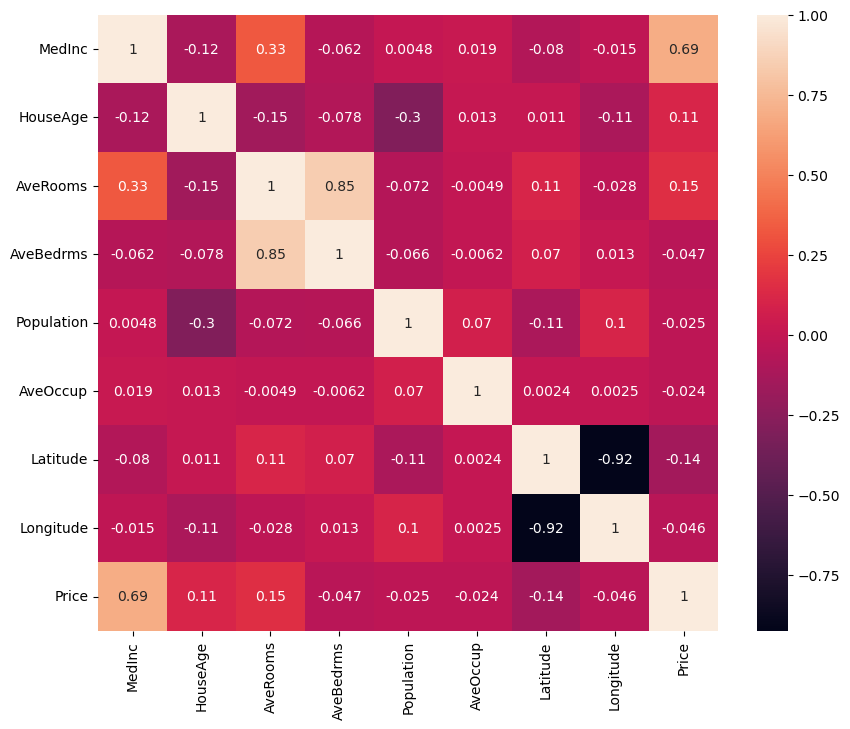

In [28]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(),annot=True,)

In [29]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [30]:
X=df.iloc[:,:-1]
X

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32


In [32]:
y=df.iloc[:,-1]
y

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: Price, Length: 20640, dtype: float64

In [33]:
from sklearn.model_selection import train_test_split

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=12)

In [43]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((14448, 8), (6192, 8), (14448,), (6192,))

In [44]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()

In [45]:
X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [50]:
X_train,X_train.shape

(array([[ 5.90176257,  1.06345827,  1.17111829, ..., -0.02405127,
         -0.74300185,  0.54110253],
        [ 1.9863587 ,  0.42715705,  0.64868423, ..., -0.02207026,
         -0.86466069,  0.74590068],
        [-0.88987832,  0.02946879, -0.33664389, ..., -0.02217033,
          1.40006543, -0.94743031],
        ...,
        [-0.93817344, -1.24313365, -0.09340514, ..., -0.07124219,
          1.65742067, -1.02735154],
        [-0.67596962, -0.76590774, -0.67697835, ..., -0.05964792,
         -0.69620998,  0.66597945],
        [ 0.25732966,  0.74530766,  0.26666029, ..., -0.05526915,
         -1.34193768,  1.25040342]]),
 (14448, 8))

## Model training 

In [51]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

Task was destroyed but it is pending!
task: <Task pending name='Task-263' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at /home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/ipykernel/utils.py:76> wait_for=<Task pending name='Task-264' coro=<_async_in_context.<locals>.preserve_context() running at /home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/ipykernel/utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/zmq/eventloop/zmqstream.py:563]>
/home/ubuntu/anaconda3/envs/ds2/lib/python3.10/site-packages/sklearn/utils/_metadata_requests.py:331: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  self._requests = requests or dict()
Task was destroyed but it is pending!
task: <Task pending name='Task-264' coro=<_async_in_context.<locals>.preserve_context() running at /home/ubuntu/anaconda3/envs/ds2/lib/python3

In [52]:
lr


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [53]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [58]:
print(lr.coef_)
print(lr.intercept_)

[ 0.81884462  0.11960784 -0.26536928  0.31055045 -0.00264837 -0.04044386
 -0.9065125  -0.87588707]
2.065175163344405


In [61]:
## find or predict some points for X_test --- finding predicte y points for the x points on test data 
y_pred=lr.predict(X_test)
y_pred

array([2.4569815 , 1.99760205, 2.29081182, ..., 2.24778256, 1.91939287,
       2.12754782])

In [62]:
y_test

6906     2.114
767      1.952
10555    2.418
17456    1.283
20617    0.708
         ...  
6023     0.933
3651     1.686
14846    1.533
1364     2.250
18990    2.500
Name: Price, Length: 6192, dtype: float64

<Axes: ylabel='Price'>

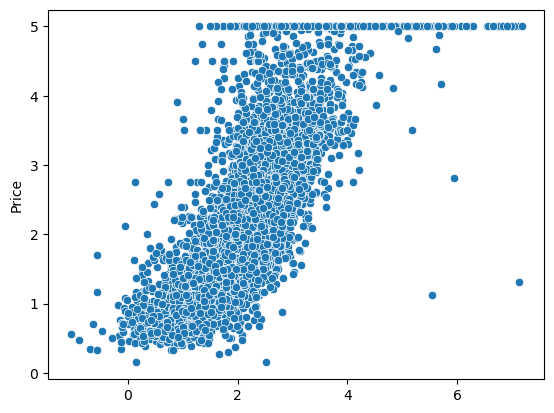

In [63]:
sns.scatterplot(x=y_pred,y=y_test)

In [77]:
residuals=y_test-y_pred
residuals

6906    -0.342982
767     -0.045602
10555    0.127188
17456   -1.423172
20617   -0.405293
           ...   
6023    -0.228180
3651    -0.219983
14846   -0.714783
1364     0.330607
18990    0.372452
Name: Price, Length: 6192, dtype: float64

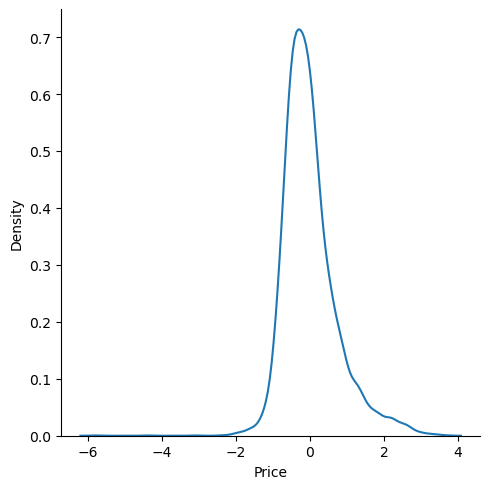

In [79]:
sns.displot(residuals,kind="kde")

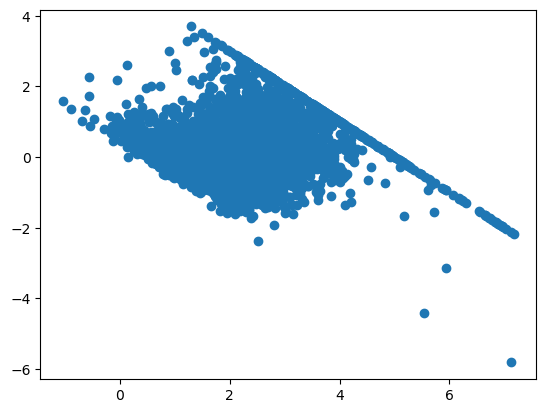

In [80]:
## SCatter plot with predictions and residual
##uniform distribution
plt.scatter(y_pred,residuals)

#### Question : what does the above plot even means ??
#### answer - ideally the model should not have any pattern .. this pattern shows that the accuracy of the model is less 

#### Question : does sum of residuals mean anything ??

## Performance metric 

In [64]:
# R square and adj r square 
from sklearn.metrics import r2_score

In [65]:
r2=r2_score(y_test,y_pred)

In [68]:
print("This is the r squared value for this data :",r2)

This is the r squared value for this data : 0.6033040298158681


In [67]:
## Adjusted R square
#display adjusted R-squared
1 - (1-r2)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.6027907566860811

In [69]:
#mse,mae,rmse
from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import mean_absolute_error as mae







In [76]:
print("Mean squared error for this data is :",mse(y_test,y_pred))
print("Mean absolute error for this data is :",mae(y_test,y_pred))
print("Root Mean squared error for this data is :",np.sqrt(mse(y_test,y_pred)))

Mean squared error for this data is : 0.5314494737169758
Mean absolute error for this data is : 0.5344154915144822
Root Mean squared error for this data is : 0.7290058118540453
